In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("../data/train")
IMG_DIR = DATA_DIR / "images"
LABEL_DIR = DATA_DIR / "labels"
TARGET_DIR = DATA_DIR / "targets"

print("images :", IMG_DIR.exists())
print("labels :", LABEL_DIR.exists())
print("targets:", TARGET_DIR.exists())

images : True
labels : True
targets: True


In [2]:
rows = []
for path in sorted(LABEL_DIR.glob("*_post_disaster.json")):
    label = json.loads(path.read_text(encoding="utf-8"))
    meta = label["metadata"]
    for b in label["features"]["xy"]:
        rows.append({
            "image_id": path.stem.replace("_post_disaster", ""),
            "disaster": meta["disaster"],
            "disaster_type": meta["disaster_type"],
            "damage": b["properties"].get("subtype", "unknown"),
        })

buildings = pd.DataFrame(rows)
print(f"Toplam bina sayısı: {len(buildings):,}")
buildings.head()

Toplam bina sayısı: 162,787


,image_id,disaster,disaster_type,damage
0,guatemala-volcano_00000000,guatemala-volcano,volcano,no-damage
1,guatemala-volcano_00000000,guatemala-volcano,volcano,no-damage
2,guatemala-volcano_00000000,guatemala-volcano,volcano,no-damage
3,guatemala-volcano_00000000,guatemala-volcano,volcano,no-damage
4,guatemala-volcano_00000000,guatemala-volcano,volcano,no-damage


In [3]:
order = ["no-damage", "minor-damage", "major-damage", "destroyed", "un-classified"]

table = pd.crosstab(
    [buildings["disaster_type"], buildings["disaster"]],
    buildings["damage"],
).reindex(columns=order, fill_value=0)

table["toplam_bina"] = table[order].sum(axis=1)
table["goruntu_cifti"] = buildings.groupby(["disaster_type", "disaster"])["image_id"].nunique()
table["hasarli_oran_%"] = (
    table[["minor-damage", "major-damage", "destroyed"]].sum(axis=1) / table["toplam_bina"] * 100
).round(1)

table

damage                             no-damage  minor-damage  major-damage  \
disaster_type disaster                                                     
earthquake    mexico-earthquake        32066           110            18   
fire          santa-rosa-wildfire       9285            78            63   
              socal-fire                8638            83            51   
flooding      hurricane-florence        4689           132          1245   
              hurricane-harvey         11423          2663          8238   
              midwest-flooding          8128           149           119   
tsunami       palu-tsunami             25455             1           571   
volcano       guatemala-volcano          639             9             9   
wind          hurricane-matthew         2515          6548          1945   
              hurricane-michael        14588          5207          1902   

damage                             destroyed  un-classified  toplam_bina  \
disaster_type disaster                                                     
earthquake    mexico-earthquake            2             75        32271   
fire          santa-rosa-wildfire       3471             53        12950   
              socal-fire                1329            374        10475   
flooding      hurricane-florence          54            326         6446   
              hurricane-harvey           401            289        23014   
              midwest-flooding            75            285         8756   
tsunami       palu-tsunami              4966            401        31394   
volcano       guatemala-volcano           25            174          856   
wind          hurricane-matthew         2147            784        13939   
              hurricane-michael          757            232        22686   

damage                             goruntu_cifti  hasarli_oran_%  
disaster_type disaster                                            
earthquake    mexico-earthquake              121             0.4  
fire          santa-rosa-wildfire            219            27.9  
              socal-fire                     408            14.0  
flooding      hurricane-florence             306            22.2  
              hurricane-harvey               300            49.1  
              midwest-flooding               244             3.9  
tsunami       palu-tsunami                   111            17.6  
volcano       guatemala-volcano               17             5.0  
wind          hurricane-matthew              223            76.3  
              hurricane-michael              334            34.7

damage
no-damage        72.1 %
minor-damage      9.2 %
major-damage      8.7 %
destroyed         8.1 %
un-classified     1.8 %
Name: count, dtype: str


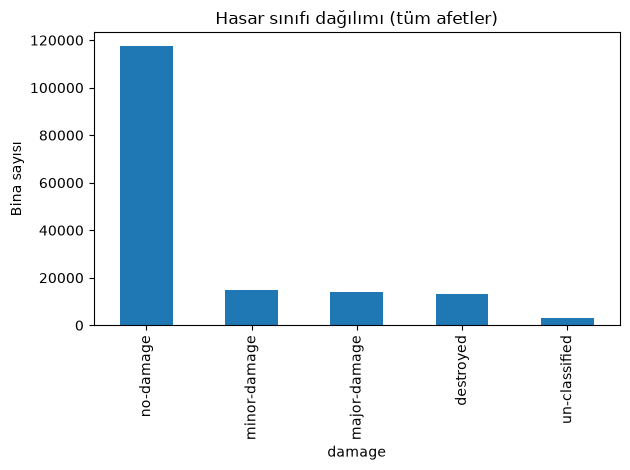

In [4]:
overall = buildings["damage"].value_counts().reindex(order, fill_value=0)
print((overall / overall.sum() * 100).round(1).astype(str) + " %")

overall.plot(kind="bar", title="Hasar sınıfı dağılımı (tüm afetler)")
plt.ylabel("Bina sayısı")
plt.tight_layout()
plt.show()

In [5]:
print(table.to_string())

damage                             no-damage  minor-damage  major-damage  destroyed  un-classified  toplam_bina  goruntu_cifti  hasarli_oran_%
disaster_type disaster                                                                                                                        
earthquake    mexico-earthquake        32066           110            18          2             75        32271            121             0.4
fire          santa-rosa-wildfire       9285            78            63       3471             53        12950            219            27.9
              socal-fire                8638            83            51       1329            374        10475            408            14.0
flooding      hurricane-florence        4689           132          1245         54            326         6446            306            22.2
              hurricane-harvey         11423          2663          8238        401            289        23014            300            49.1

In [6]:
Path("../results").mkdir(exist_ok=True)
table.to_csv("../results/faz2_afet_hasar_dagilimi.csv", encoding="utf-8-sig")
print("Kaydedildi")

Kaydedildi


no-damage     : 2,515 bina
minor-damage  : 6,548 bina
major-damage  : 1,945 bina
destroyed     : 2,147 bina


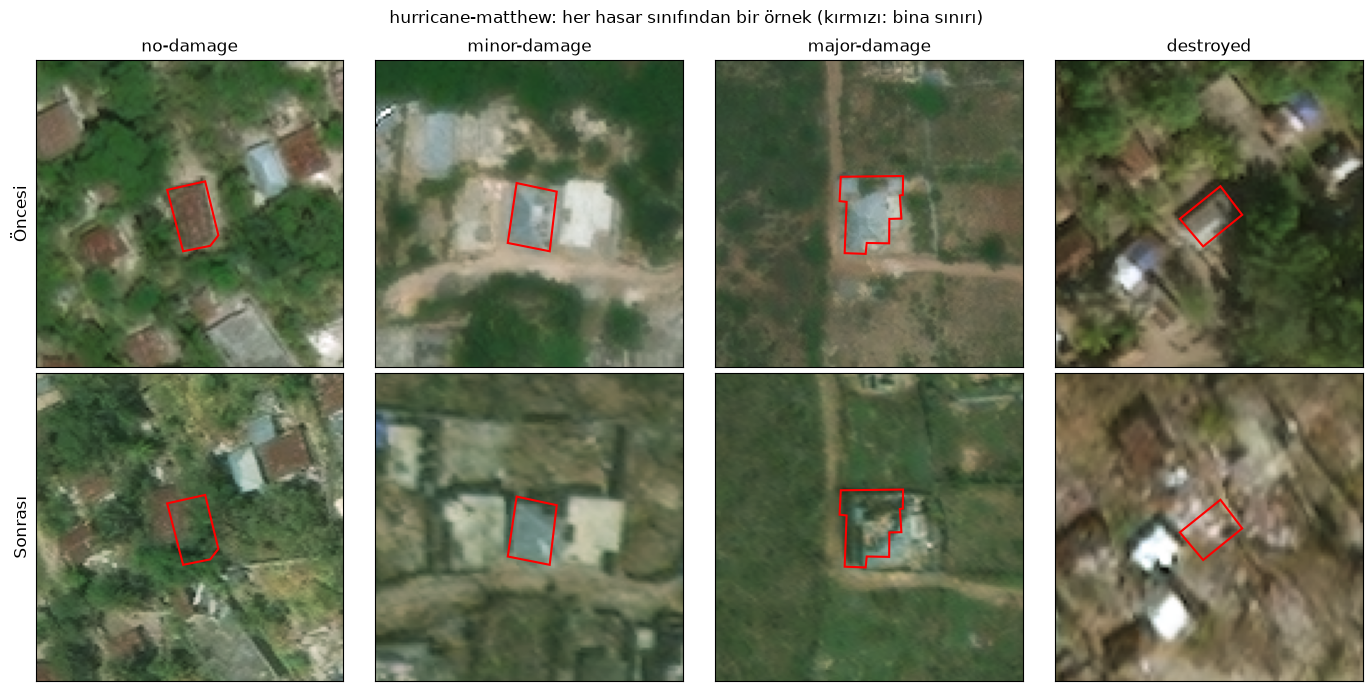

In [7]:
import re
import random
import matplotlib.patches as patches

EVENT = "hurricane-matthew"
CLASSES = ["no-damage", "minor-damage", "major-damage", "destroyed"]

def wkt_to_xy(wkt):
    """'POLYGON ((x y, x y, ...))' metnini [(x, y), ...] listesine çevirir."""
    nums = [float(v) for v in re.findall(r"-?\d+(?:\.\d+)?", wkt)]
    return list(zip(nums[0::2], nums[1::2]))

# 1) Matthew'deki binaları sınıflarına göre topla
examples = {c: [] for c in CLASSES}
for path in sorted(LABEL_DIR.glob(f"{EVENT}_*_post_disaster.json")):
    label = json.loads(path.read_text(encoding="utf-8"))
    for b in label["features"]["xy"]:
        damage = b["properties"].get("subtype")
        if damage in examples:
            xy = wkt_to_xy(b["wkt"])
            xs, ys = zip(*xy)
            area = (max(xs) - min(xs)) * (max(ys) - min(ys))
            examples[damage].append((path.stem.replace("_post_disaster", ""), xy, area))

for c in CLASSES:
    print(f"{c:14s}: {len(examples[c]):,} bina")

# 2) Her sınıftan, iyi görünsün diye büyük binalar arasından rastgele birini seç ve çiz
random.seed(42)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for col, cls in enumerate(CLASSES):
    candidates = sorted(examples[cls], key=lambda e: e[2])
    image_id, xy, _ = random.choice(candidates[len(candidates) // 2:])

    xs, ys = zip(*xy)
    cx, cy = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
    half = max(max(xs) - min(xs), max(ys) - min(ys)) * 1.5 + 20

    for row, phase in enumerate(["pre", "post"]):
        img = Image.open(IMG_DIR / f"{image_id}_{phase}_disaster.png")
        W, H = img.size
        box = (int(max(cx - half, 0)), int(max(cy - half, 0)),
               int(min(cx + half, W)), int(min(cy + half, H)))
        ax = axes[row, col]
        ax.imshow(img.crop(box))
        poly = [(x - box[0], y - box[1]) for x, y in xy]
        ax.add_patch(patches.Polygon(poly, fill=False, edgecolor="red", linewidth=1.5))
        ax.set_xticks([])
        ax.set_yticks([])

    axes[0, col].set_title(cls)

axes[0, 0].set_ylabel("Öncesi", fontsize=12)
axes[1, 0].set_ylabel("Sonrası", fontsize=12)
plt.suptitle(f"{EVENT}: her hasar sınıfından bir örnek (kırmızı: bina sınırı)")
plt.tight_layout()
plt.show()

count    162787.0
mean         49.0
std          80.5
min           4.3
5%           12.9
25%          23.7
50%          37.0
75%          51.1
95%          90.6
99%         452.0
max        1033.7
Name: size, dtype: float64


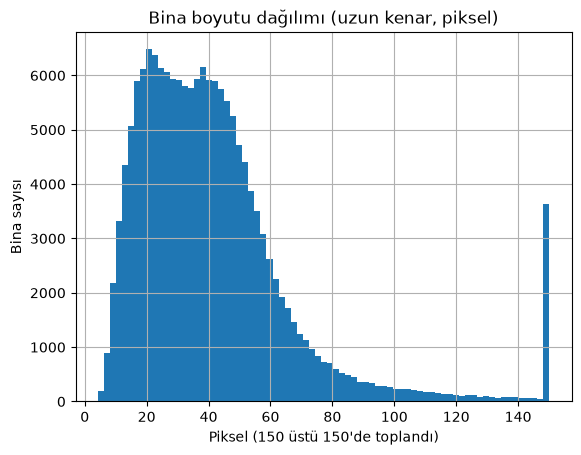

In [8]:
rows = []
for path in sorted(LABEL_DIR.glob("*_post_disaster.json")):
    label = json.loads(path.read_text(encoding="utf-8"))
    meta = label["metadata"]
    image_id = path.stem.replace("_post_disaster", "")
    for b in label["features"]["xy"]:
        xy = wkt_to_xy(b["wkt"])
        if not xy:
            continue
        xs, ys = zip(*xy)
        rows.append({
            "image_id": image_id,
            "disaster": meta["disaster"],
            "disaster_type": meta["disaster_type"],
            "damage": b["properties"].get("subtype", "unknown"),
            "uid": b["properties"].get("uid"),
            "x_min": min(xs), "y_min": min(ys),
            "x_max": max(xs), "y_max": max(ys),
        })

buildings = pd.DataFrame(rows)
buildings["width"] = buildings["x_max"] - buildings["x_min"]
buildings["height"] = buildings["y_max"] - buildings["y_min"]
buildings["size"] = buildings[["width", "height"]].max(axis=1)

# Faz 3'te tekrar kullanmak için kaydet (data/ GitHub'a gitmez)
Path("../data/processed").mkdir(exist_ok=True)
buildings.to_csv("../data/processed/buildings.csv", index=False)

print(buildings["size"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(1))

buildings["size"].clip(upper=150).hist(bins=75)
plt.title("Bina boyutu dağılımı (uzun kenar, piksel)")
plt.xlabel("Piksel (150 üstü 150'de toplandı)")
plt.ylabel("Bina sayısı")
plt.show()

150 pikselden büyük: 3,564 bina (%2.2)

Afetlere göre:
disaster
hurricane-harvey       1123
mexico-earthquake      1093
palu-tsunami            462
socal-fire              401
hurricane-michael       211
hurricane-florence      176
santa-rosa-wildfire      54
midwest-flooding         42
hurricane-matthew         2
dtype: int64 

Hasar sınıfına göre:
damage
no-damage        2732
major-damage      474
destroyed         162
minor-damage      155
un-classified      41
Name: count, dtype: int64 

Görüntü sınırını aşanlar:
                           image_id        damage     x_min     y_min  \
5388    hurricane-florence_00000388  major-damage -8.726267 -8.741435   
6916    hurricane-florence_00000485  major-damage -8.887379 -8.973798   
7425      hurricane-harvey_00000001     no-damage -6.000000 -6.000000   
7512      hurricane-harvey_00000002     no-damage -3.164775 -6.000000   
8038      hurricane-harvey_00000012     no-damage -6.000000 -6.000000   
...                             ...    

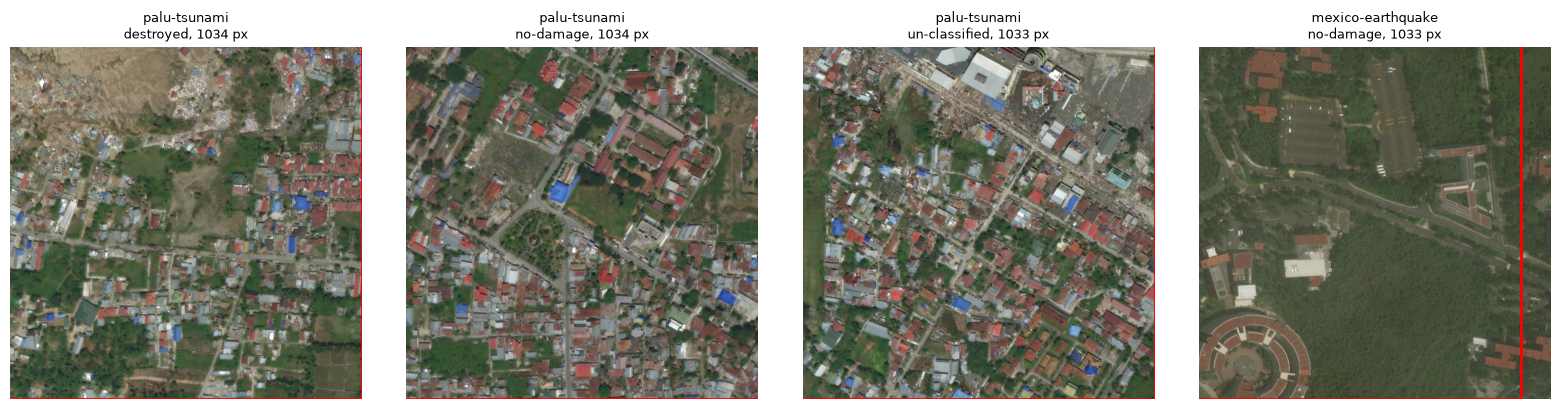

In [9]:
big = buildings[buildings["size"] > 150]
print(f"150 pikselden büyük: {len(big):,} bina (%{len(big) / len(buildings) * 100:.1f})\n")

print("Afetlere göre:")
print(big.groupby("disaster").size().sort_values(ascending=False), "\n")

print("Hasar sınıfına göre:")
print(big["damage"].value_counts(), "\n")

print("Görüntü sınırını aşanlar:")
print(buildings.loc[buildings["size"] > 1024, ["image_id", "damage", "x_min", "y_min", "x_max", "y_max"]])

# En büyük 4 poligonu, tüm görüntü üzerinde göster
sample = big.sort_values("size", ascending=False).drop_duplicates("image_id").head(4)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (_, r) in zip(axes, sample.iterrows()):
    img = Image.open(IMG_DIR / f"{r['image_id']}_post_disaster.png")
    ax.imshow(img)
    ax.add_patch(patches.Rectangle((r["x_min"], r["y_min"]), r["width"], r["height"],
                                   fill=False, edgecolor="red", linewidth=2))
    ax.set_title(f"{r['disaster']}\n{r['damage']}, {r['size']:.0f} px", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
w, h = buildings["width"], buildings["height"]
short_side = pd.concat([w, h], axis=1).min(axis=1)

rule_full = buildings["size"] > 1000
rule_thin = short_side < 3
rule_long = (buildings["size"] / short_side.clip(lower=1)) > 10

bad = rule_full | rule_thin | rule_long
buildings["is_bad_polygon"] = bad

print(f"Görüntüyü kaplayan : {rule_full.sum():,}")
print(f"Çok ince (<3 px)   : {rule_thin.sum():,}")
print(f"Aşırı uzun (>10:1) : {rule_long.sum():,}")
print(f"Toplam şüpheli     : {bad.sum():,} (%{bad.mean() * 100:.2f})\n")
print("Şüphelilerin hasar sınıfları:")
print(buildings.loc[bad, "damage"].value_counts())

buildings.to_csv("../data/processed/buildings.csv", index=False)
print("\nbuildings.csv güncellendi (is_bad_polygon sütunu eklendi)")

Görüntüyü kaplayan : 185
Çok ince (<3 px)   : 75
Aşırı uzun (>10:1) : 97
Toplam şüpheli     : 330 (%0.20)

Şüphelilerin hasar sınıfları:
damage
no-damage        244
major-damage      36
un-classified     29
destroyed         14
minor-damage       7
Name: count, dtype: int64

buildings.csv güncellendi (is_bad_polygon sütunu eklendi)
